# Customer churn: experiments and retention decisions

This notebook explains the executed experiment and reads its aggregate evidence. Source code in `src/churn/` owns the reproducible training workflow; the notebook provides analysis without hidden model state. All figures and tables come from actual runs. See `reports/results.md` for the complete audit, search space, uncertainty and limitations.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from churn.data import DATA_FILE, load_data, split_indices, profile_groups

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
REPORTS = ROOT / "reports"
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})

## 1. Reproduce training separately from evaluation

Five outer grouped, stratified folds evaluate each family. Three inner folds tune by AP. Each pipeline learns imputation, encoding, scaling and spline knots within its training fold. Original class weights are recalculated per fit. The compact search evaluates 8 settings for each improved family.

Set the switch below to `True` to run the full experiment into a separate ignored directory. The test stage refuses a second evaluation in the same directory. Comparing frozen alternatives is descriptive; do not change model choices after reading holdout results.

In [2]:
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    from churn.experiment import develop, evaluate
    from threadpoolctl import threadpool_limits
    with threadpool_limits(limits=1):
        output = REPORTS / "reproduction"
        develop(ROOT / "data/raw" / DATA_FILE, output)
        evaluate(ROOT / "data/raw" / DATA_FILE, output)
    from churn.verify import verify
    verify(output, REPORTS)
else:
    print("Inspecting the completed reference experiment; no models are refitted.")

Inspecting the completed reference experiment; no models are refitted.


## 2. Reproduce the original baseline

The three original settings are recreated on their historical seed-42 split. These scores provide continuity with the starting solution. They must not be compared as if paired with the fresh holdout. A fair comparison refits the same original methods on the current development set.

In [3]:
historical = pd.read_csv(REPORTS / "historical_reproduction.csv")
display(historical[["model", "roc_auc", "average_precision", "precision", "recall", "f1"]].round(4))

               model  roc_auc  average_precision  precision  recall      f1
0  original_logistic   0.8417             0.6331     0.5043  0.7834  0.6136
1      original_tree   0.8141             0.5486     0.5140  0.7834  0.6208
2  original_boosting   0.8451             0.6581     0.5127  0.8102  0.6280

## 3. Nested validation and model selection

Choose the highest mean outer AP, with a predeclared 0.005 practical tolerance favoring simpler families. Fold SD is descriptive, not a confidence interval. The final holdout evaluates the family-selection choice as well as its tuned settings.

In [4]:
cv = pd.read_csv(REPORTS / "cv_summary.csv")
display(cv.sort_values("ap_mean", ascending=False).round(4))
selection = json.loads((REPORTS / "selection.json").read_text())
display(pd.Series({"selected_family": selection["champion"],
                   "selection_rule": selection["selection_metric"],
                   "threshold": selection["thresholds"][selection["champion"]],
                   "development_rows": selection["development_rows"],
                   "holdout_rows": selection["test_rows"]}, name="Frozen choices").to_frame())
print(json.dumps(selection["final_parameters"], indent=2))

{
  "dummy": {},
  "original_logistic": {},
  "original_tree": {},
  "original_boosting": {},
  "tuned_logistic": {
    "model__C": 10.0,
    "model__class_weight": null
  },
  "spline_logistic": {
    "model__C": 0.1,
    "model__class_weight": null
  },
  "hist_boosting": {
    "features__enabled": false,
    "model__l2_regularization": 1.0,
    "model__learning_rate": 0.05,
    "model__max_leaf_nodes": 7
  }
}


               model  ap_mean   ap_sd  auc_mean  auc_sd
5    spline_logistic   0.6596  0.0365    0.8456  0.0130
1      hist_boosting   0.6540  0.0314    0.8425  0.0117
2  original_boosting   0.6539  0.0293    0.8441  0.0121
6     tuned_logistic   0.6481  0.0411    0.8427  0.0131
3  original_logistic   0.6465  0.0418    0.8423  0.0132
4      original_tree   0.5524  0.0305    0.8159  0.0126
0              dummy   0.2659  0.0119    0.5000  0.0000

                                                     Frozen choices
selected_family                                     spline_logistic
selection_rule    nested CV average precision; 0.005 simplicity ...
threshold                                                  0.308185
development_rows                                               5634
holdout_rows                                                   1409

## 4. What helped?

The nonlinear spline family improves mean outer AP over tuned linear logistic regression. Histogram boosting does not surpass it; engineered features are absent from the final best histogram model. Final inner-search scores below describe selection, not unbiased performance. There is no isolated accuracy claim for imputation changes or any individual engineered feature.

In [5]:
for family in ["tuned_logistic", "spline_logistic", "hist_boosting"]:
    search = pd.read_csv(REPORTS / f"search_{family}.csv")
    print(family)
    display(search[["params", "mean_test_score", "std_test_score", "rank_test_score"]]
            .sort_values("rank_test_score").head(8))

tuned_logistic
spline_logistic
hist_boosting


                                              params  ...  rank_test_score
6    {'model__C': 10.0, 'model__class_weight': None}  ...                1
4     {'model__C': 1.0, 'model__class_weight': None}  ...                2
7  {'model__C': 10.0, 'model__class_weight': 'bal...  ...                3
5  {'model__C': 1.0, 'model__class_weight': 'bala...  ...                4
2     {'model__C': 0.1, 'model__class_weight': None}  ...                5
3  {'model__C': 0.1, 'model__class_weight': 'bala...  ...                6
1  {'model__C': 0.01, 'model__class_weight': 'bal...  ...                7
0    {'model__C': 0.01, 'model__class_weight': None}  ...                8

[8 rows x 4 columns]

                                              params  ...  rank_test_score
2     {'model__C': 0.1, 'model__class_weight': None}  ...                1
6    {'model__C': 10.0, 'model__class_weight': None}  ...                2
4     {'model__C': 1.0, 'model__class_weight': None}  ...                3
3  {'model__C': 0.1, 'model__class_weight': 'bala...  ...                4
5  {'model__C': 1.0, 'model__class_weight': 'bala...  ...                5
7  {'model__C': 10.0, 'model__class_weight': 'bal...  ...                6
1  {'model__C': 0.01, 'model__class_weight': 'bal...  ...                7
0    {'model__C': 0.01, 'model__class_weight': None}  ...                8

[8 rows x 4 columns]

                                              params  ...  rank_test_score
0  {'features__enabled': False, 'model__l2_regula...  ...                1
4  {'features__enabled': True, 'model__l2_regular...  ...                2
1  {'features__enabled': False, 'model__l2_regula...  ...                3
5  {'features__enabled': True, 'model__l2_regular...  ...                4
2  {'features__enabled': False, 'model__l2_regula...  ...                5
6  {'features__enabled': True, 'model__l2_regular...  ...                6
3  {'features__enabled': False, 'model__l2_regula...  ...                7
7  {'features__enabled': True, 'model__l2_regular...  ...                8

[8 rows x 4 columns]

## 5. Decision threshold and class imbalance

The spline model is refitted without balanced weights. A development nested-OOF F1 optimum supplies a stated contact policy; this changes precision and recall, not ranking. The optimized development F1 is not an unbiased estimate. F1 is useful as a transparent example, but real deployment needs contact costs, margins and response rates.

In [6]:
thresholds = pd.read_csv(REPORTS / "development_thresholds.csv")
display(thresholds[["model", "threshold", "precision", "recall", "f1", "brier"]].round(4))
results = pd.read_csv(REPORTS / "test_metrics.csv")
display(results[["model", "operating_point", "threshold", "roc_auc", "average_precision", "precision", "recall", "f1", "brier"]].round(4))

               model  threshold  precision  recall      f1   brier
0              dummy     0.5000     0.0000  0.0000  0.0000  0.1953
1  original_logistic     0.5224     0.5263  0.7891  0.6314  0.1676
2      original_tree     0.6441     0.5100  0.7824  0.6175  0.1785
3  original_boosting     0.5379     0.5358  0.7797  0.6351  0.1639
4     tuned_logistic     0.2682     0.5191  0.8057  0.6314  0.1372
5    spline_logistic     0.3082     0.5207  0.7897  0.6276  0.1414
6      hist_boosting     0.2363     0.5051  0.8338  0.6291  0.1376

                model operating_point  threshold  ...  recall      f1   brier
0               dummy         default     0.5000  ...  0.0000  0.0000  0.1940
1   original_logistic         default     0.5000  ...  0.8140  0.6351  0.1589
2   original_logistic          oof_f1     0.5224  ...  0.8005  0.6429  0.1589
3       original_tree         default     0.5000  ...  0.7871  0.6307  0.1669
4   original_boosting         default     0.5000  ...  0.7951  0.6317  0.1543
5   original_boosting          oof_f1     0.5379  ...  0.7790  0.6444  0.1543
6      tuned_logistic         default     0.5000  ...  0.5930  0.6386  0.1289
7      tuned_logistic          oof_f1     0.2682  ...  0.8140  0.6385  0.1289
8     spline_logistic         default     0.5000  ...  0.5687  0.6365  0.1251
9     spline_logistic          oof_f1     0.3082  ...  0.7898  0.6659  0.1251
10      hist_boosting         default     0.5000  ...  0.5795  0.6380  0.1261
11      hist_boosting          oof_f1     0.2363  ...  0.8329  0

## 6. Holdout ranking and uncertainty

AP is average precision, not trapezoidal PR integration. The class-stratified paired bootstrap uses 2,000 resamples and reports conditional intervals for fitted-model differences. These intervals exclude retraining and model-selection uncertainty. Small differences on a single static sample do not establish a general model advantage.

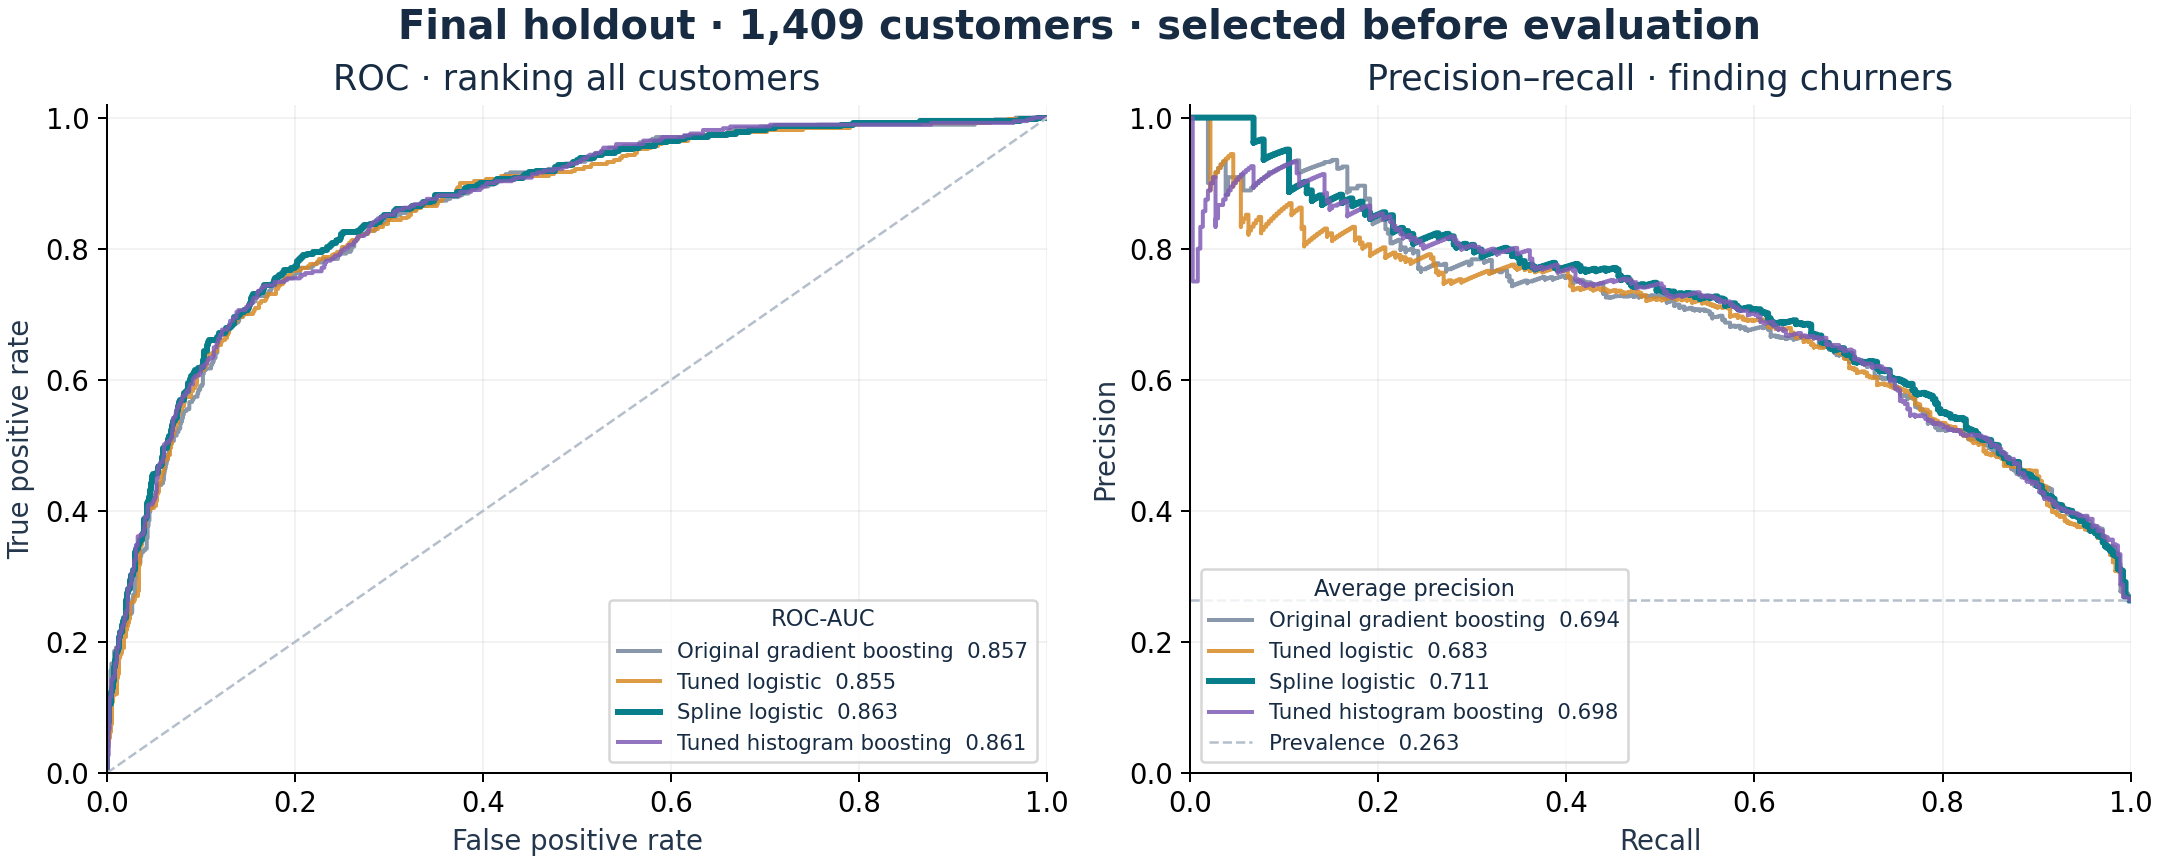

                                      lower    upper
champion_roc_auc                    0.84143  0.88416
champion_ap                         0.66875  0.75164
delta_roc_auc_vs_original_boosting  0.00030  0.01100
delta_ap_vs_original_boosting       0.00272  0.03167

In [7]:
display(Image(filename=str(REPORTS / "figures/ranking_curves.png")))
intervals = json.loads((REPORTS / "bootstrap_intervals.json").read_text())
display(pd.DataFrame(intervals).T.round(5))

## 7. Workload and contact capacity

Confusion counts make the business trade-off tangible. The selected threshold reduces unnecessary contacts relative to the original policy at similar recall. A separate, predeclared top-20% ranking rule describes a smaller campaign budget. Identified churners are not the same as saved customers.

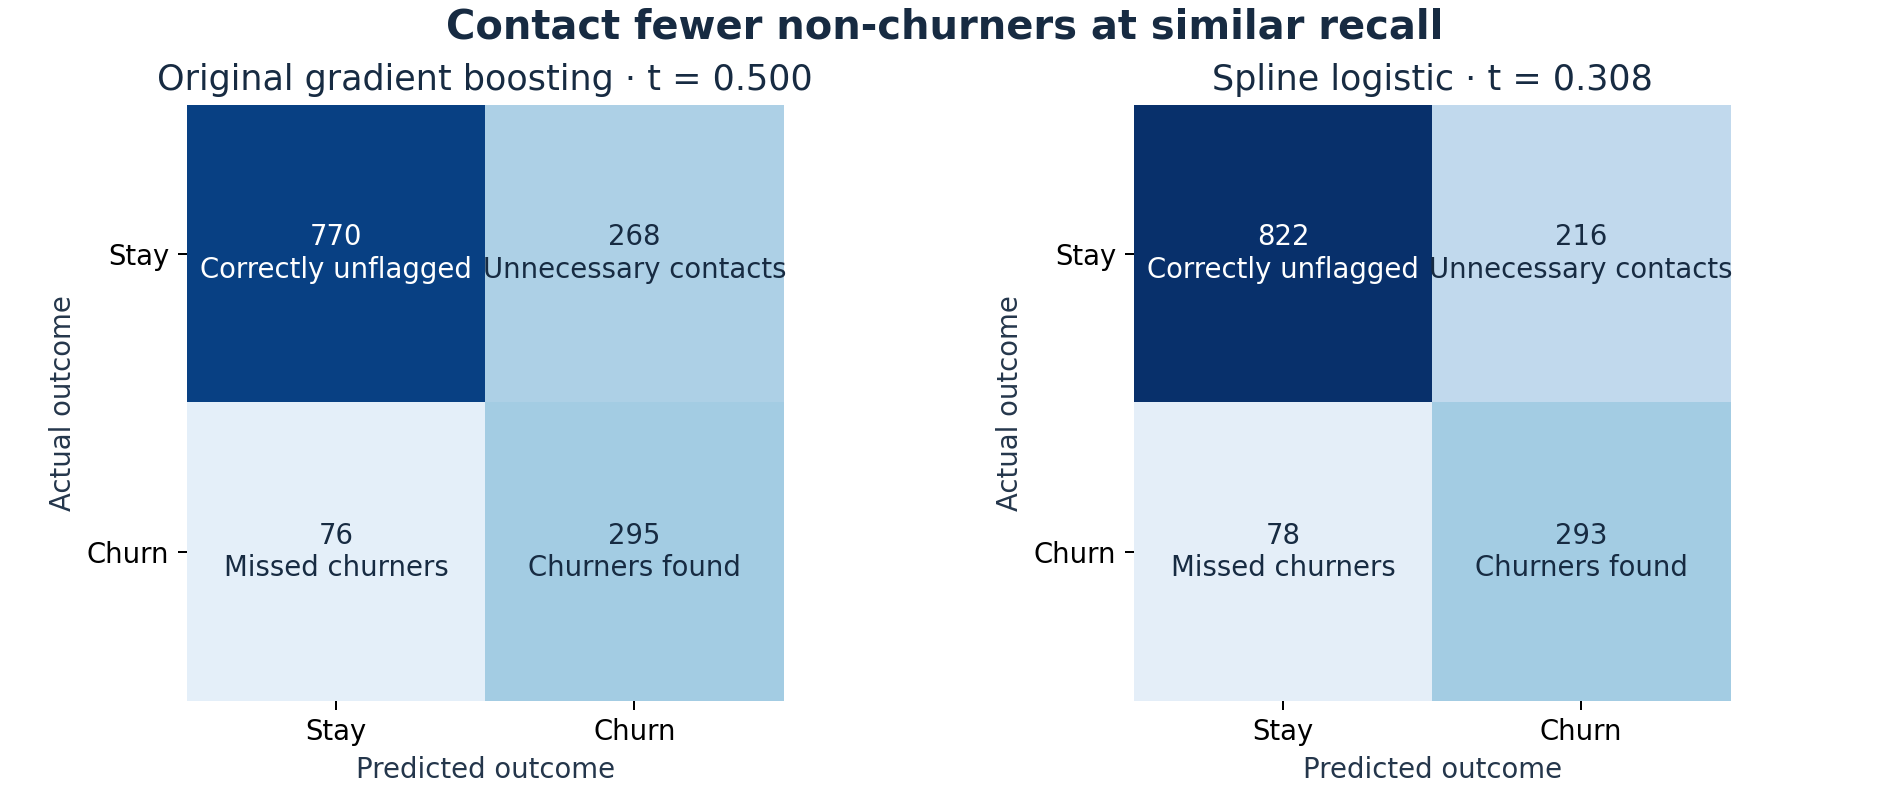

                 Top 20% contact budget
contacted                    282.000000
churners_found               205.000000
precision                      0.726950
recall                         0.552561
lift                           2.760844
test_churn_rate                0.263307

In [8]:
display(Image(filename=str(REPORTS / "figures/confusion_matrices.png")))
display(pd.Series(json.loads((REPORTS / "capacity.json").read_text()), name="Top 20% contact budget").to_frame())

## 8. Interpretability

Permutation importance is measured on outer validation folds after tuning within the corresponding training fold. Shuffle original columns through the entire pipeline so all derived representations change together. The chart shows mean AP decrease and SD across five folds × five permutations. Correlation and unrealistic shuffled combinations limit interpretation. Importance gives neither causal direction nor intervention effect.

                    mean     std
feature                         
tenure            0.2139  0.0294
Contract          0.0503  0.0117
InternetService   0.0222  0.0123
MonthlyCharges    0.0187  0.0156
PaymentMethod     0.0092  0.0095
OnlineSecurity    0.0089  0.0042
TechSupport       0.0085  0.0077
PaperlessBilling  0.0074  0.0066
TotalCharges      0.0053  0.0051
MultipleLines     0.0041  0.0047
OnlineBackup      0.0040  0.0055
PhoneService      0.0015  0.0023
SeniorCitizen     0.0011  0.0038
StreamingTV       0.0004  0.0035
Dependents        0.0001  0.0013
DeviceProtection -0.0000  0.0013
Partner          -0.0003  0.0009
gender           -0.0005  0.0016
StreamingMovies  -0.0005  0.0024

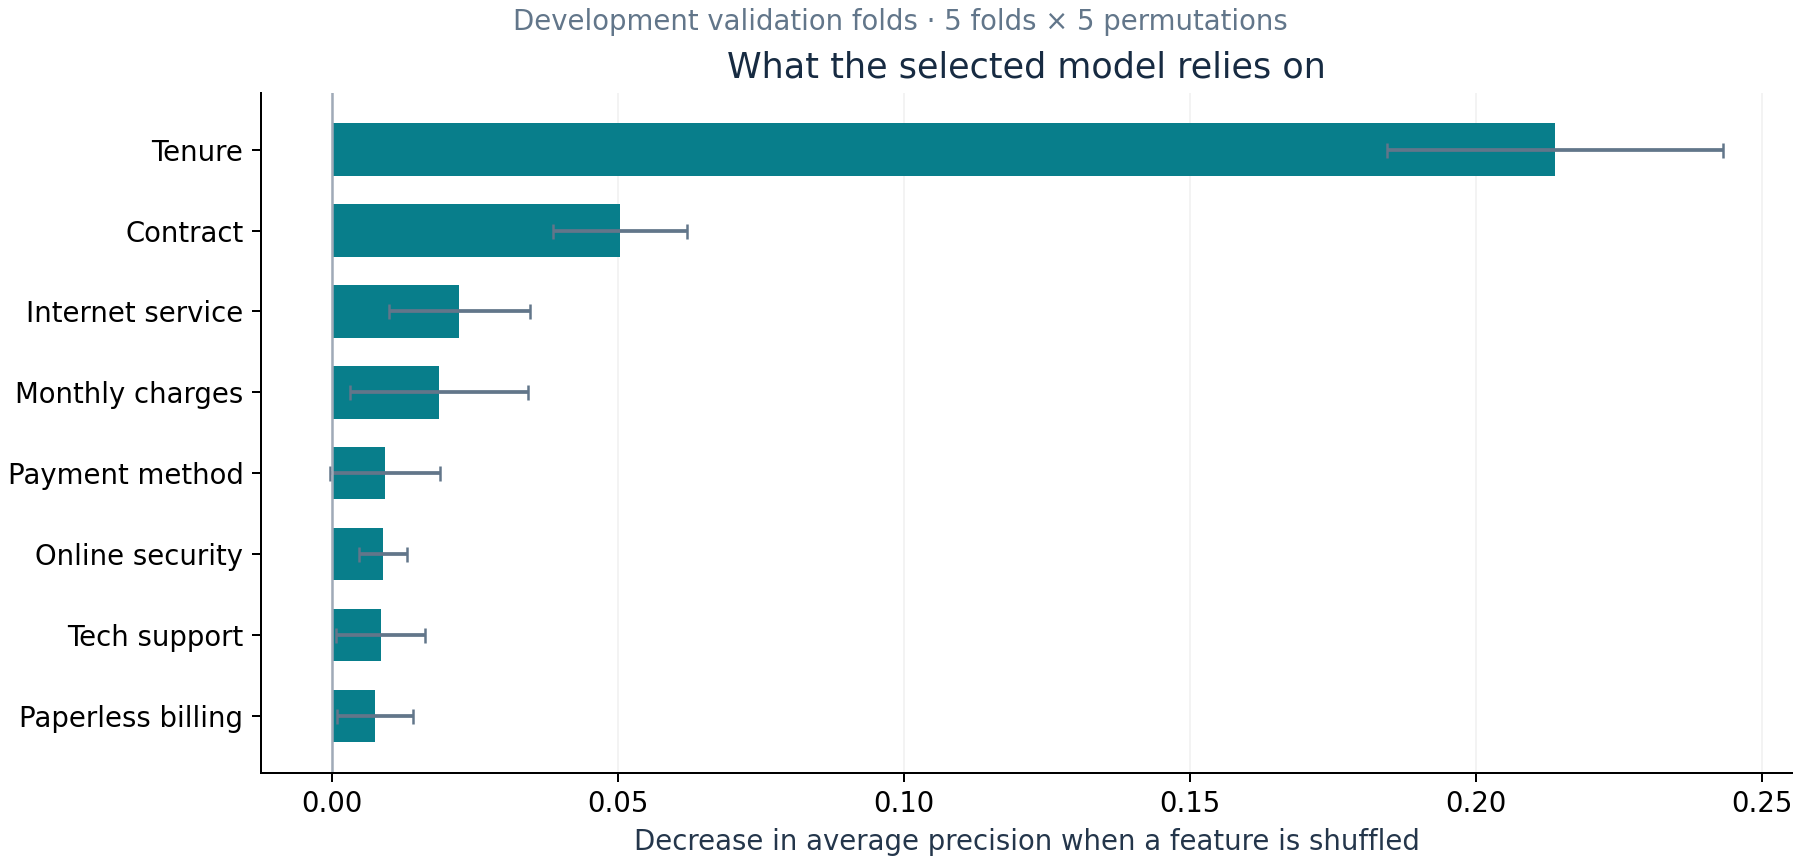

In [9]:
importance = pd.read_csv(REPORTS / "permutation_importance.csv")
display(importance.groupby("feature").ap_drop.agg(["mean", "std"])
        .sort_values("mean", ascending=False).round(4))
display(Image(filename=str(REPORTS / "figures/feature_importance.png")))

## 9. Recommendation and limits

Use risk ranking to choose an outreach queue consistent with operational capacity. Investigate onboarding, contract and service patterns. Randomize appropriate high-risk customers into outreach and control groups, then measure incremental retained margin before scaling offers.

This fictional benchmark lacks timestamps and treatment outcomes. Historical exploration means the new test is untouched only by the current experiment; excluded repeated profiles and historical evaluation rows slightly restrict its population. Procedural leakage safeguards do not establish that every source field was collected before churn. External/time-based validation, subgroup checks, calibrated probabilities and causal campaign tests remain necessary. No revenue benefit or churn reduction is estimated.